<h1> Introduction to Rdkit and Machine Learning for (analytical) Chemists <h1>

<h5>

Table of Content:

1. **Introduction to RDKit**  
1.1   Visualize molecules  
1.2   Clean molecules       
1.3   Featurizing molecules      
2. **Machine Learning Pipeline**  
2.1  Load data  
2.2  Explore and clean data  
2.3  Featurizing molecules   
2.4  Choose, build and Train model  
2.5  Evaluate model  
2.6  Save / load / use / deploy model  

</h5>


# **1 Introduction to RDKit**

**<h3> What is RDKit?**  
<h5>
RDKit is an open-source cheminformatics library for working with molecules in Python.  

**It allows you to**:
- Read and write molecular fomats (e.g. SMILES)
- Visualize molecules
- Calculate molecular properties (descriptors)
- Generate molecular fingerprints
- And much more ...

> **In short: RDKit helps you turn chemical structures into something a computer can understand.**

In [1]:
# Install Rdkit
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 84.9 MB/s  0:00:00


In [2]:
# Import some RDKIT modules
from rdkit import Chem                   # the core module
from rdkit.Chem import Draw              # drawing molecules
from rdkit.Chem import Descriptors       # molecular descriptors (MW, LogP, etc)
from rdkit.Chem import AllChem           # fingerprints and more
from rdkit import DataStructs            # similarity (Tanimoto, etc)
from rdkit.Chem import PandasTools       # rdkit + Pandas
from rdkit.Chem import rdMolDescriptors  # more advances descriptors
from rdkit.Chem import Lipinski          # Lipinski's Rule of Five descriptors

**What are SMILES?**  
SMILES (Simplified Molecular Input Line Entry System) are a way to represent chemical structures as a simple text string.  

Instead of drawing a molecule, you write it as a line of text:
- Ethanol → `CCO`
- Benzene → `c1ccccc1`
- Caffeine → `Cn1cnc2c1c(=O)n(C)c(=O)n2C`  

SMILES encode:
- Atoms (C, O, N, etc.)
- Bonds (single, double `=`, triple `#`)
- Branches `()`
- Rings (numbers like `1`)

> **A SMILES string is a compact, computer-readable description of a molecule.**
> **SMILES are the starting point of almost every ML project involving molecules.**

## **1.1 Visualize molecules**

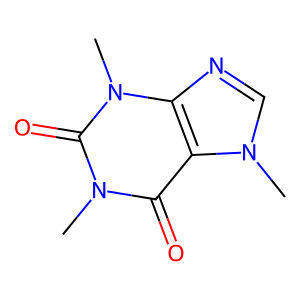

In [9]:
smiles = 'Cn1cnc2c1c(=O)n(C)c(=O)n2C'   # Define the SMILES string for caffeine
mol = Chem.MolFromSmiles(smiles)        # Convert the SMILES string to RDKit Mol object
Draw.MolToImage(mol)                                     # Display the RDKit Mol object

# Tip: the drawing of the molecule can be copied!

Converting SMILES to an RDKit Mol Object (MolFromSmiles)

In RDKit, molecules are represented as Mol objects. A Mol object is a structured and chemically aware representation of a molecule that allows us to perform calculations, visualization, and machine learning.


In [11]:
# Lets create a Dataframe containing 10 drugs (names and smiles)

import pandas as pd # Import the pandas library for data manipulation

common_drugs = {
    'Name': [
        'Aspirin', 'Paracetamol', 'Ibuprofen', 'Amoxicillin', 'Omeprazole',
        'Lisinopril', 'Metformin', 'Levothyroxine', 'Atorvastatin', 'Diazepam'
    ],
    'SMILES': [
        'CC(=O)Oc1ccccc1C(=O)O', # Aspirin
        'CC(=O)Nc1ccc(O)cc1',   # Paracetamol
        'CC(C)CC(C(=O)O)c1ccc(C)cc1', # Ibuprofen
        'CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(=O)N2C1C(=O)O', # Amoxicillin
        'Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1', # Omeprazole
        'NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O', # Lisinopril
        'CN(C)C(=N)NC(=N)N',   # Metformin
        'Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I', # Levothyroxine
        'CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C', # Atorvastatin
        'CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1', # Diazepam
    ]
}

df_common_drugs = pd.DataFrame(common_drugs) # Convert list into a DataFrame
df_common_drugs # Dataframe

,Name,SMILES
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O
1,Paracetamol,CC(=O)Nc1ccc(O)cc1
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1
5,Lisinopril,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O
6,Metformin,CN(C)C(=N)NC(=N)N
7,Levothyroxine,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I
8,Atorvastatin,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C
9,Diazepam,CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1


In [13]:
# Add mol objects to the dataframe
df_common_drugs['mol'] = df_common_drugs['SMILES'].apply(Chem.MolFromSmiles)
df_common_drugs

,Name,SMILES,mol
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7afcf940aea0>
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7afcf940af10>
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7afcf940aff0>
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7afcf940b060>
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7afcf940b0d0>
5,Lisinopril,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7afcf940b140>
6,Metformin,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7afcf940b1b0>
7,Levothyroxine,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7afcf940b220>
8,Atorvastatin,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C,<rdkit.Chem.rdchem.Mol object at 0x7afcf940b290>
9,Diazepam,CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1,<rdkit.Chem.rdchem.Mol object at 0x7afcf940b300>


In [14]:
# For drawing all molecules we first need to convert
# the mol objects and the names to a list
mols = df_common_drugs['mol'].tolist()
names = df_common_drugs['Name'].tolist()

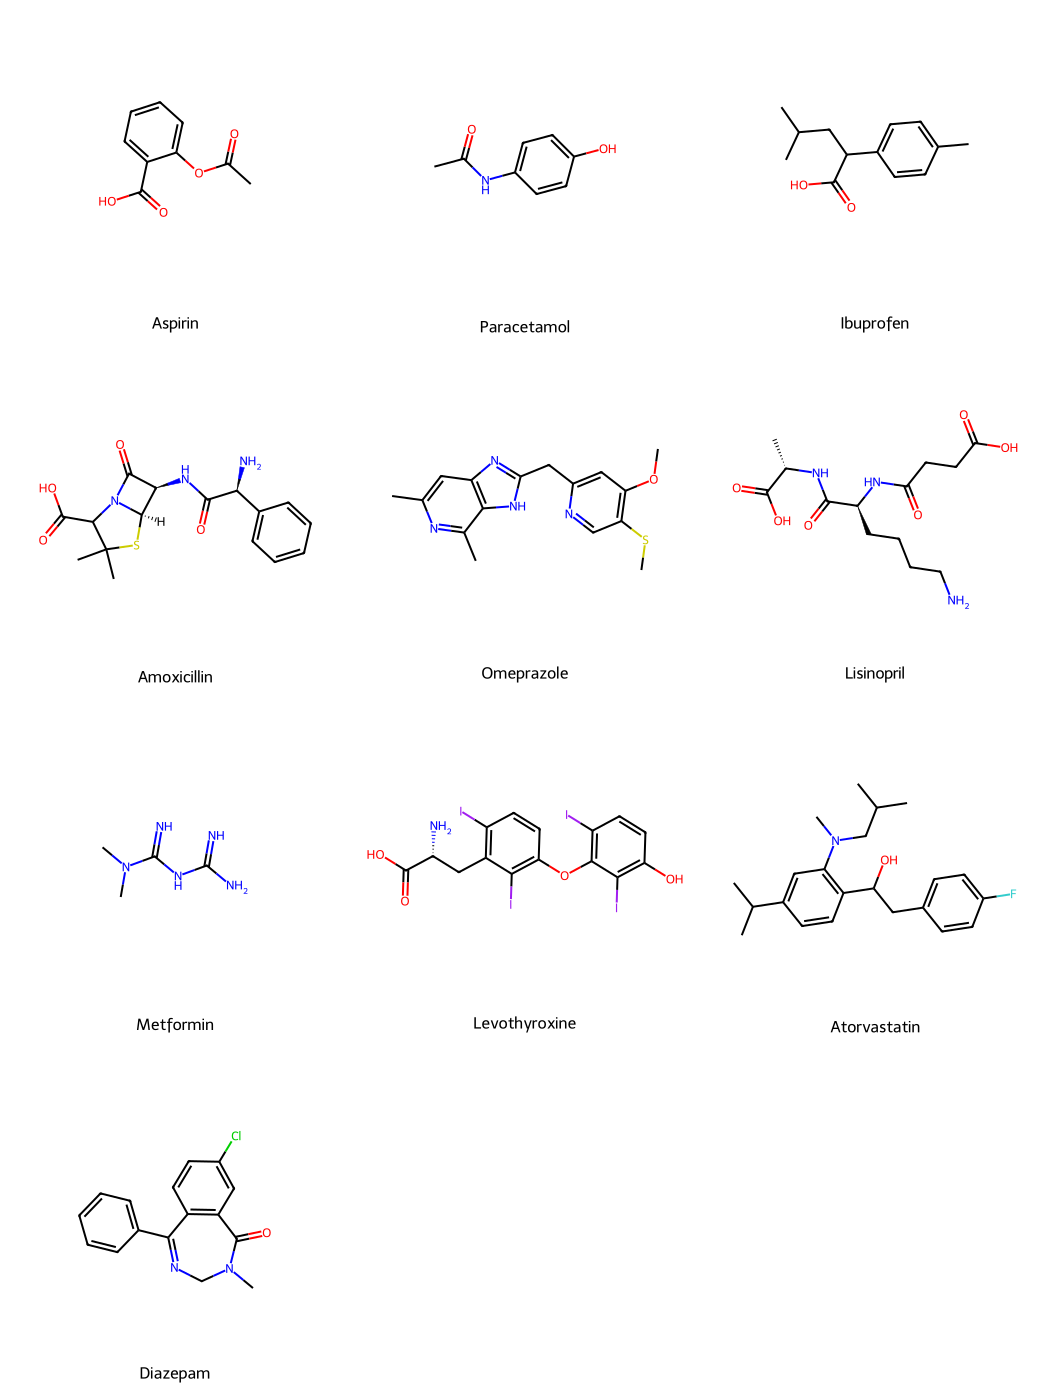

In [15]:
# Plot all mol objects
img = Draw.MolsToGridImage(
    mols,                       # mol objects
    molsPerRow=3,               # Adjust as needed
    subImgSize=(350, 350),      # Image size
    legends=names               # add labels
)
img

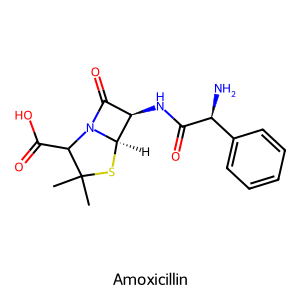

In [16]:
# Draw the selected molecule with its name as a legend
# Remember in Python we start to count from 0

molecule_number = 3 # select a molecule by its index in df_molecules
mol = df_common_drugs['mol'].iloc[molecule_number]
name = df_common_drugs['Name'].iloc[molecule_number]

img = Draw.MolToImage(
    mol,                        # RDKit Mol object
    legend=name                 # Add the molecule's name as a legend
)
img

## **1.2 Cleaning Molecule Dataset**

Cleaning Molecule Dataset

In real-world datasets, molecular data represented as SMILES is often inconsistent and noisy. Before using this data for analysis or machine learning, it is essential to clean and standardize it to ensure reliability and consistency.

Common issues in raw SMILES datasets include missing values, invalid structures, formatting problems (such as extra spaces), duplicate entries, and different SMILES representations of the same molecule. Some entries may also contain multiple molecules (e.g. salts or mixtures), which may give issues for machine learning.

Most important steps in the cleaning process

1. Remove missing data

2. Fix formatting issues

3. Validate SMILES

4. Convert smiles to mol objects

5. Convert smiles to canonical SMILES

6. Remove duplicates (optional)

7. Handle salts and mixtures (having a dot in the smiles)  

    
**Key takeaway**

>Cleaning molecular data is a crucial step in cheminformatics. Often time consuming.
It ensures that the dataset is accurate, consistent, and ready for analysis or machine learning, which ultimately leads to more reliable and meaningful results.

In [17]:
# Lets create a dataframe containing raw data which must be cleaned !!
raw_data = {
    'SMILES': [
        'CC(=O)Oc1ccccc1C(=O)O',  # Aspirin /
        'O=C(C)Oc1ccccc1C(=O)O',   # Aspirin / in a different smiles notation
        'O=C(O)c1ccccc1OC(=O)C',   # Aspirin / in a different smiles notation
        None,
        '    CC(=O)Nc1ccc(O)cc1   ',   # Paracetamol / with extra white space
        'CC(C)CC(C(=O)O)c1ccc(C)cc1', # Ibuprofen
        'NOT A SMILES', # invalid smiles
        '', # No data
        None,
        '123456', # invalid data
        'CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(=O)N2C1C(=O)O', # Amoxicillin
        'Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1', # Omeprazole
        'NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O', # Lisinopril
        'CN(C)C(=N)NC(=N)N',   # Metformin
        'Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I', # Levothyroxine
        'CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C', # Atorvastatin
        None,
        'CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1.CCC' # Diazepam salt
        'CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1' # Diazepam
        'CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1' # Diazepam / duplicate
    ]
}

df_raw_data = pd.DataFrame(raw_data) # Convert list into a DataFrame
df_raw_data # Dataframe

,SMILES
0,CC(=O)Oc1ccccc1C(=O)O
1,O=C(C)Oc1ccccc1C(=O)O
2,O=C(O)c1ccccc1OC(=O)C
3,None
4,CC(=O)Nc1ccc(O)cc1
5,CC(C)CC(C(=O)O)c1ccc(C)cc1
6,NOT A SMILES
7,
8,None
9,123456


Lets clean the molecules in this dataset

In [ ]:
# COUNT MOLECULES
len(df_raw_data) # The number of data entries in the original raw data set !

18

In [ ]:
# REMOVE MISSING DATA
df_raw_data = df_raw_data.dropna(subset=['SMILES'])
len(df_raw_data)

15

In [ ]:
# FIX FORMATTING ISSUES - Strip whitespace
df_raw_data.loc[:, "SMILES"] = df_raw_data["SMILES"].str.strip()

In [ ]:
# REMOVE EMPTY STRINGS
df_raw_data = df_raw_data[df_raw_data["SMILES"] != ""].copy()
len(df_raw_data)

14

In [ ]:
# CONVERT SMILES TO MOL OBJECTS
df_raw_data["mol"] = [Chem.MolFromSmiles(s) for s in df_raw_data["SMILES"]]
df_raw_data

[12:07:18] SMILES Parse Error: syntax error while parsing: NOT
[12:07:18] SMILES Parse Error: check for mistakes around position 3:
[12:07:18] NOT
[12:07:18] ~~^
[12:07:18] SMILES Parse Error: Failed parsing SMILES 'NOT' for input: 'NOT'
[12:07:18] SMILES Parse Error: syntax error while parsing: 123456
[12:07:18] SMILES Parse Error: check for mistakes around position 1:
[12:07:18] 123456
[12:07:18] ^
[12:07:18] SMILES Parse Error: Failed parsing SMILES '123456' for input: '123456'


,SMILES,mol
0,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341fe60>
1,O=C(C)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341d230>
2,O=C(O)c1ccccc1OC(=O)C,<rdkit.Chem.rdchem.Mol object at 0x7c077341f220>
4,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fc30>
5,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fca0>
6,NOT A SMILES,None
9,123456,None
10,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c077341fbc0>
11,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fb50>
12,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341fae0>


In [ ]:
# REMOVE INVALID SMILES (where mol = None)
df_raw_data = df_raw_data[df_raw_data["mol"].notnull()].copy()
len(df_raw_data)

12

In [ ]:
# CONVERT SMILES TO CANONICAL SMILES
# BY CONVERTING MOL OBJECTS BACK TO CANONICAL SMILES
canonical_smiles = []
for mol in df_raw_data["mol"]:
    canonical_smiles.append(Chem.MolToSmiles(mol, canonical=True))

df_raw_data["smiles_canonical"] = canonical_smiles
df_raw_data

,SMILES,mol,smiles_canonical
0,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341fe60>,CC(=O)Oc1ccccc1C(=O)O
1,O=C(C)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341d230>,CC(=O)Oc1ccccc1C(=O)O
2,O=C(O)c1ccccc1OC(=O)C,<rdkit.Chem.rdchem.Mol object at 0x7c077341f220>,CC(=O)Oc1ccccc1C(=O)O
4,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fc30>,CC(=O)Nc1ccc(O)cc1
5,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fca0>,Cc1ccc(C(CC(C)C)C(=O)O)cc1
10,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c077341fbc0>,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...
11,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fb50>,COc1cc(Cc2nc3cc(C)nc(C)c3[nH]2)ncc1SC
12,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341fae0>,C[C@H](NC(=O)[C@H](CCCCN)NC(=O)CCC(=O)O)C(=O)O
13,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7c077341fa70>,CN(C)C(=N)NC(=N)N
14,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7c077341fa00>,N[C@H](Cc1c(I)ccc(Oc2c(I)ccc(O)c2I)c1I)C(=O)O


In [ ]:
# REMOVE DUPLICATE SMILES
df_raw_data = df_raw_data.drop_duplicates(subset="smiles_canonical")
len(df_raw_data)

10

In [ ]:
# REMOVE SMILES CONTAINING DOTS (.) E.G. SALTS / MIXTURES
df_raw_data = df_raw_data[~df_raw_data["SMILES"].str.contains(r"\.")].copy()
len(df_raw_data)

9

In [ ]:
df_raw_data

,SMILES,mol,smiles_canonical
0,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341fe60>,CC(=O)Oc1ccccc1C(=O)O
4,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fc30>,CC(=O)Nc1ccc(O)cc1
5,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fca0>,Cc1ccc(C(CC(C)C)C(=O)O)cc1
10,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c077341fbc0>,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...
11,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c077341fb50>,COc1cc(Cc2nc3cc(C)nc(C)c3[nH]2)ncc1SC
12,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c077341fae0>,C[C@H](NC(=O)[C@H](CCCCN)NC(=O)CCC(=O)O)C(=O)O
13,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7c077341fa70>,CN(C)C(=N)NC(=N)N
14,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7c077341fa00>,N[C@H](Cc1c(I)ccc(Oc2c(I)ccc(O)c2I)c1I)C(=O)O
15,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C,<rdkit.Chem.rdchem.Mol object at 0x7c077341f990>,CC(C)CN(C)c1cc(C(C)C)ccc1C(O)Cc1ccc(F)cc1


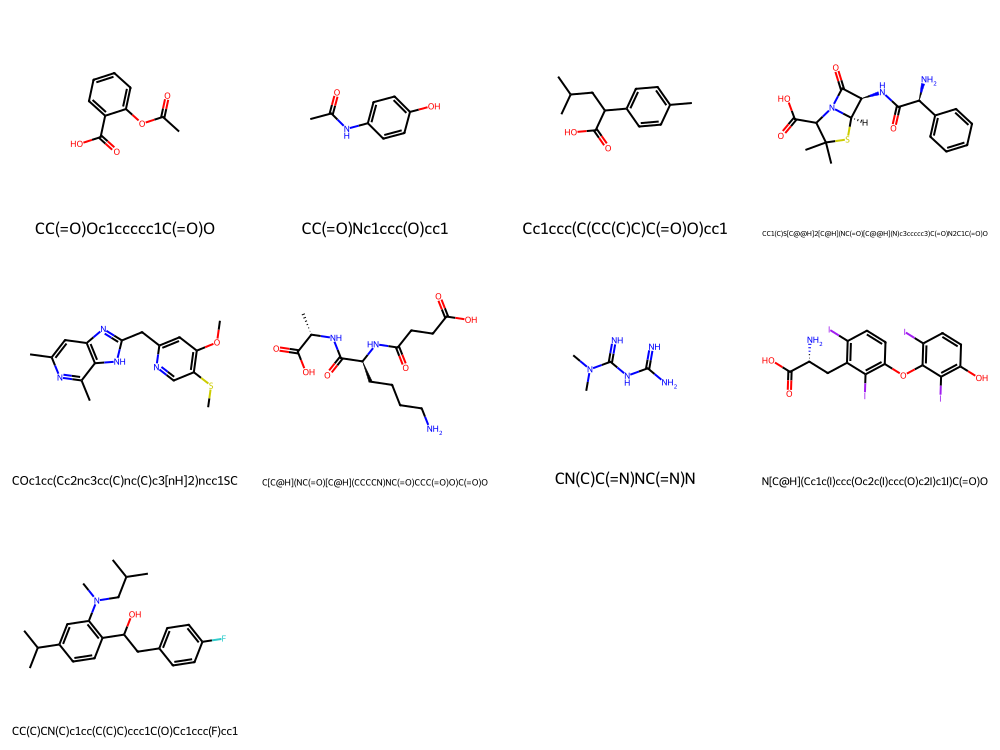

In [ ]:
# Draw the cleaned dataset !
Draw.MolsToGridImage(
    df_raw_data["mol"].tolist(),
    molsPerRow=4,
    legends=df_raw_data["smiles_canonical"].tolist(),
    subImgSize=(250,250)
    )

## **1.3 Featurizing molecules**

**Featurization of Molecules for Machine Learning**

Machine learning models cannot work directly with molecules or SMILES strings.  
In general, they require **numerical input**. Therefore, molecules must be converted into numbers; this process is called **featurization**.

In cheminformatics, there are three main and widely used approaches to featurize molecules:

---

**1. Molecular Descriptors**

Descriptors are **calculated numerical properties** of a molecule.

Examples:
- Molecular weight  
- Number of atoms  
- LogP (lipophilicity)  
- Number of hydrogen bond donors/acceptors  

> Descriptors summarize the molecule using a set of meaningful chemical properties.

- Easy to understand  
- Interpretable  
- May miss detailed structural information  

---

**2. Molecular Fingerprints**

Fingerprints are **binary vectors (lists of 0s and 1s)** that encode the presence or absence of structural features.

Example:
- A vector like: `[0,1,0,1,1,0,...]`

The most common type is:
- **Morgan fingerprints (circular fingerprints)**

> Each bit represents a specific structural pattern in the molecule.

+ Very popular in machine learning  
+ Captures structural information  
+ Works well for similarity and prediction tasks  
+ Hard to interpret (what each bit means is not always clear)

---

**3. Molecular Graphs**

A molecule can also be represented as a **graph**:

- Atoms → nodes  
- Bonds → edges  

This representation is used in:
- **Graph Neural Networks (GNNs)**

> Instead of predefined features, the model learns directly from the structure.

- Most flexible and powerful  
- Captures full molecular structure  
- More complex and advanced  

---

**Summary**

| Method        | Idea                          | Complexity
|--------------|-------------------------------|------------|
| Descriptors  | Chemical properties           | Low        |
| Fingerprints | Structural patterns (bits)    | Medium     |
| Mol Graphs   | Full molecular structure      | High       |

---

**Key takeaway**

>Featurization = **convert molecules into numbers**  
>The three main approaches are:
>-    **1 Descriptors**
>-    **2 Fingerprints**
>-    **3 Molecular graphs**

### **1.3.1 Molecular descriptors**

By using RDKIT more than **200 descriptors** can be calculated and used as input for ML.
For a first introduction, it is best to focus on a small set of intuitive and widely used descriptors:

- Molecular Weight (MolWt)
The size of the molecule in terms of mass.

- LogP (MolLogP)
A measure of how hydrophobic (fat-loving) or hydrophilic (water-loving) a molecule is.

- TPSA (Topological Polar Surface Area)
Indicates the polarity of a molecule and is related to solubility and permeability.

- Number of Atoms (NumAtoms)
A simple measure of molecular size.

- Hydrogen Bond Donors (NumHDonors)
Number of atoms that can donate a hydrogen bond.

- Hydrogen Bond Acceptors (NumHAcceptors)
Number of atoms that can accept a hydrogen bond.

- Number of Rotatable Bonds (NumRotatableBonds)
Indicates molecular flexibility.

In [ ]:
# Our dataset
df_common_drugs

,Name,SMILES,mol
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5070>
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5a80>
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5bd0>
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c07733c44a0>
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5af0>
5,Lisinopril,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5f50>
6,Metformin,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6030>
7,Levothyroxine,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7c07733c60a0>
8,Atorvastatin,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6110>
9,Diazepam,CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6180>


In [ ]:
# Lets calculate the descriptor: molecular weight (mw)
# and add to our dataframe

mw_list = [] # define the list (now empty) for all molecular weights
for mol in df_common_drugs["mol"]:
    mw_list.append(Descriptors.MolWt(mol))

# Add list of all calculated molecular weight to our dataframe
df_common_drugs["mw"] = mw_list
df_common_drugs

,Name,SMILES,mol,mw
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5070>,180.159
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5a80>,151.165
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5bd0>,206.285
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c07733c44a0>,349.412
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5af0>,314.414
5,Lisinopril,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5f50>,317.342
6,Metformin,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6030>,129.167
7,Levothyroxine,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7c07733c60a0>,776.872
8,Atorvastatin,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6110>,343.486
9,Diazepam,CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6180>,284.746


In [ ]:
# Lets calculate the descriptor: logP weight
# and add to our dataframe

logp_list = [] # define the list (now empty) for all logp values
for mol in df_common_drugs["mol"]:
    logp_list.append(Descriptors.MolLogP(mol))

# Add list of all calculated molecular weight to our dataframe
df_common_drugs["logP"] = logp_list
df_common_drugs

,Name,SMILES,mol,mw,logP
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5070>,180.159,1.31010
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5a80>,151.165,1.35060
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5bd0>,206.285,3.20932
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c07733c44a0>,349.412,0.31810
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5af0>,314.414,3.29104
5,Lisinopril,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5f50>,317.342,-0.94570
6,Metformin,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6030>,129.167,-1.03416
7,Levothyroxine,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7c07733c60a0>,776.872,4.55730
8,Atorvastatin,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6110>,343.486,5.31740
9,Diazepam,CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6180>,284.746,3.22050


In [ ]:
# We can also add multiple descriptors at the same time to our dataframe
# Lets add the number of Hydrogen donors and acceptors
donors_list = []
acceptors_list = []
for mol in df_common_drugs["mol"]:
    donors_list.append(Lipinski.NumHDonors(mol))
    acceptors_list.append(Lipinski.NumHAcceptors(mol))
df_common_drugs["H_donors"] = donors_list
df_common_drugs["H_acceptors"] = acceptors_list
df_common_drugs

,Name,SMILES,mol,mw,logP,H_donors,H_acceptors
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5070>,180.159,1.31010,1,3
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5a80>,151.165,1.35060,2,2
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5bd0>,206.285,3.20932,1,1
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c07733c44a0>,349.412,0.31810,3,5
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5af0>,314.414,3.29104,1,5
5,Lisinopril,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5f50>,317.342,-0.94570,5,5
6,Metformin,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6030>,129.167,-1.03416,4,2
7,Levothyroxine,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7c07733c60a0>,776.872,4.55730,3,4
8,Atorvastatin,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6110>,343.486,5.31740,1,2
9,Diazepam,CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6180>,284.746,3.22050,0,2


In [ ]:
# ADD 200 MOLECULAR DESCRIPTORS TO THE DATAFRAME

# CALCULATE ALL RDKIT DESCRIPTORS AND ADD THEM TO THE DATAFRAME
all_descriptors = [Descriptors.CalcMolDescriptors(mol) for mol in df_common_drugs['mol']]

# CREATE A NEW DATAFRAME CONTAINING ALL DESCRIPTORS
df_descriptors = pd.DataFrame(all_descriptors)

# ADD NEW COLUMNS TO THE DATAFRAME
df_combinatie = pd.concat([df_common_drugs, df_descriptors], axis=1)

df_combinatie.head()

,Name,SMILES,mol,mw,logP,H_donors,H_acceptors,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5070>,180.159,1.31010,1,3,10.611948,10.611948,0.016019,...,0,0,0,0,0,0,0,0,0,0
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5a80>,151.165,1.35060,2,2,10.524469,10.524469,0.115102,...,0,0,0,0,0,0,0,0,0,0
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5bd0>,206.285,3.20932,1,1,11.120348,11.120348,0.369815,...,0,0,0,0,0,0,0,0,0,0
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c07733c44a0>,349.412,0.31810,3,5,12.334173,12.334173,0.374515,...,1,0,0,0,0,0,0,0,0,0
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5af0>,314.414,3.29104,1,5,5.406916,5.406916,0.637092,...,1,0,0,0,0,0,0,0,0,0


### **1.3.2 Molecular Fingerprints**

Molecular Fingerprints

What are Molecular Fingerprints?

>Molecular fingerprints are a way to represent a molecule as a **vector of numbers (usually 0s and 1s)**.

Instead of working with the chemical structure directly, we convert a molecule into a **numerical format** that machine learning models can understand.

Example (simplified):

Molecule → Fingerprint  
`CCO` → `[0, 1, 0, 1, 1, 0, ...]`

Each position (bit) in the fingerprint represents the **presence or absence of a certain structural pattern** in the molecule.

---

Why are Fingerprints Important?

Machine learning models cannot (easily) work with:
- SMILES strings  
- Chemical drawings  

They require **numerical input (features)**.

Molecular fingerprints:
- Encode **chemical structure** into numbers  
- Allow comparison between molecules  
- Are widely used in cheminformatics and ML  

>They are the **most important feature type** for many ML models in chemistry.

---

Types of Fingerprints (focus of this course)

In this course, we mainly use:

- **Morgan fingerprints (circular fingerprints)**
  - Based on atom neighborhoods
  - Very popular and powerful
  - Also known as ECFP (Extended Connectivity Fingerprints)

---

How it fits in the ML workflow

SMILES → RDKit mol object → **Fingerprint → ML model**

---

Key Idea
> Fingerprints translate chemistry into data.

In [ ]:
from rdkit.Chem import rdFingerprintGenerator

# SMILES for caffeine
smiles = "Cn1cnc2c1c(=O)n(C)c(=O)n2C"

# Convert SMILES to mol object
mol = Chem.MolFromSmiles(smiles)

# Create Morgan fingerprint (new method)
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=1, fpSize=1024)
fp = fpgen.GetFingerprint(mol)

# Convert fingerprint to list
fp_list = list(fp)

# Print results
print("First 20 bits:", fp_list[:20])
print("Number of bits set to 1:", sum(fp_list))

First 20 bits: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Number of bits set to 1: 16


**Fingerprint Settings: Radius and fpSize**

When creating a Morgan fingerprint, two important parameters are:

**1. Radius**
- Defines how far the algorithm looks around each atom  
- Radius = 1 → only direct neighbors  
- Radius = 2 → neighbors of neighbors (most commonly used)  
- Radius = 3 → larger chemical environment  

>Larger radius = more structural information, but also more complexity

---

**2. fpSize**
- Defines the size (lenght) of the fingerprint (number of bits)  
- Common values: 512, 1024, 2048  


>Larger fingerprint:
- More space to store information  
- Less chance of overlap (collisions)  
- But more computational cost  

---

**Practical Choice**
- **Radius = 2** → good balance (standard choice)  
- **Length = 1024 or 2048** → commonly used  

---

> Start simple: radius = 2 and fpSize = 1024 works well for most ML projects.

Full structure of Caffeine:


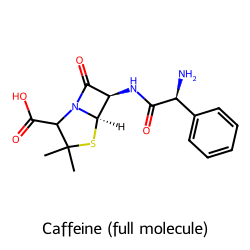


Number of active bits: 45

Associated substructures per active bit:


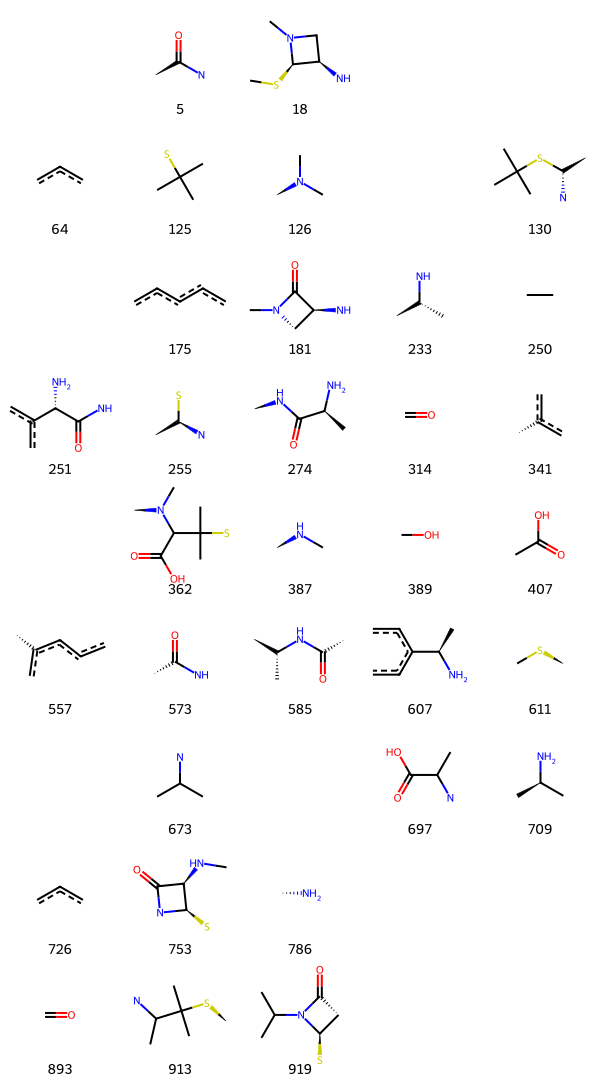

In [18]:
# @title { display-mode: "form" }
# @markdown Code not important. This is only to show the active bits and the whole molecule.
from rdkit.Chem import rdFingerprintGenerator, Draw, AllChem
from IPython.display import display

# Example molecule (caffeine)
#smiles = "Cn1cnc2c1c(=O)n(C)c(=O)n2C"
#mol = Chem.MolFromSmiles(smiles)

print("Full structure of Caffeine:")
display(Draw.MolToImage(mol, size=(250, 250), legend="Caffeine (full molecule)"))

# Get Morgan fingerprint + bit info
bitInfo = {}
fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=1024, bitInfo=bitInfo)

# Get active bits (bits set to 1)
on_bits = list(fp.GetOnBits())
print("\nNumber of active bits:", len(on_bits))

# Visualize the active substructures
bits_to_show = on_bits[:1024]
submols = []
legends = []
for bit in bits_to_show:
    atom_id, radius = bitInfo[bit][0]
    env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, atom_id)
    submol = Chem.PathToSubmol(mol, env)
    submols.append(submol)
    legends.append(str(bit))

# Draw the fragments
print("\nAssociated substructures per active bit:")
display(Draw.MolsToGridImage(
    submols,
    molsPerRow=5,
    subImgSize=(120, 120),
    legends=legends
))

In [ ]:
# Calculate fingerprints of all molecules in a DayaFrame
# and add them to the DataFrame
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
morgan_fingerprints = []
for mol_obj in df_common_drugs["mol"]:
    fp = fpgen.GetFingerprint(mol_obj)
    morgan_fingerprints.append(list(fp))

df_common_drugs["morgan_fp"] = morgan_fingerprints
df_common_drugs

,Name,SMILES,mol,mw,logP,H_donors,H_acceptors,morgan_fp
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5070>,180.159,1.31010,1,3,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, ..."
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5a80>,151.165,1.35060,2,2,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,Ibuprofen,CC(C)CC(C(=O)O)c1ccc(C)cc1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5bd0>,206.285,3.20932,1,1,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,Amoxicillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@@H](N)c3ccccc3)C(...,<rdkit.Chem.rdchem.Mol object at 0x7c07733c44a0>,349.412,0.31810,3,5,"[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,Omeprazole,Cc1nc(C)c2[nH]c(Cc3ncc(SC)c(OC)c3)nc2c1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5af0>,314.414,3.29104,1,5,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
5,Lisinopril,NCCCC[C@H](NC(=O)CCC(=O)O)C(=O)N[C@@H](C)C(=O)O,<rdkit.Chem.rdchem.Mol object at 0x7c07733c5f50>,317.342,-0.94570,5,5,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
6,Metformin,CN(C)C(=N)NC(=N)N,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6030>,129.167,-1.03416,4,2,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
7,Levothyroxine,Oc1ccc(I)c(Oc2ccc(I)c(C[C@@H](N)C(=O)O)c2I)c1I,<rdkit.Chem.rdchem.Mol object at 0x7c07733c60a0>,776.872,4.55730,3,4,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
8,Atorvastatin,CC(C)c1ccc(C(O)Cc2ccc(F)cc2)c(c1)N(C)CC(C)C,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6110>,343.486,5.31740,1,2,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
9,Diazepam,CN1C(=O)c2cc(Cl)ccc2C(c2ccccc2)=NC1,<rdkit.Chem.rdchem.Mol object at 0x7c07733c6180>,284.746,3.22050,0,2,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


## **1.4 RDKit Summary**


**Key Takeaways & Summary**

In this section, we explored the essentials of **RDKit** to handle and prepare chemical structures for machine learning. Here are the core concepts covered:

1. **SMILES & Molecular Objects**
   - SMILES are compact, line-text representations of molecules (e.g., `CCO` for ethanol).
   - RDKit converts these strings into chemically aware **Mol objects** (`Chem.MolFromSmiles`), which form the foundation for all subsequent calculations and visualizations.

2. **Data Cleaning is Crucial**
   - Raw SMILES datasets often contain duplicates, formatting issues, salts, and invalid structures.
   - **Essential cleaning pipeline:** Remove nulls/empty strings → Strip whitespace → Validate with RDKit → Standardize structures to **canonical SMILES** → Remove duplicates and separate salts/mixtures.

3. **Featurization (Turning Chemistry into Numbers)**
   - Machine learning algorithms require numerical input. We examined the two main featurization strategies:
     - **Molecular Descriptors:** Calculated physical and chemical properties (e.g., Molecular Weight, LogP, Hydrogen Bond Donors/Acceptors). Great for simple, interpretable features.
     - **Molecular Fingerprints (Morgan/ECFP):** Fixed-length binary vectors (usually 1024 or 2048 bits) encoding the presence or absence of specific atom neighborhoods and local substructures. This is the industry standard for ML molecular classification and regression.

# **-------------------------------------------------**

# **2 Machine Learning**

**MACHINE LEARNING EXAMPLES WILL BE GIVEN IN A SEPARATE NOTEBOOKS**

<h1>Machine Learning Pipeline<h1>

<h5> 1. Define the application </h5>
<h5> 2. Load data (smiles + target values)</h5>
<h5> 3. Explore and clean data  </h5>
<h5> 4. Featurize molecules (descriptors / fingerprints) </h5>
<h5> 5. Featurize scaling </h5>
<h5> 6. Split data (training and test set) </h5>
<h5> 7. Choose and build ML model (classification / regression) </h5>
<h5> 8. Train model on training set </h5>
<h5> 9. Evaluate model on test set </h5>
<h5> 10. Improve model (optimization, hyperparamater tuning, etc) </h5>
<h5> 11. Save, Load, Use model for predictions on new data </h5>
<h5> 12. Optional: Deploy model </h5>

<h5>

>**Machine Learning Pipeline:  
Data → Features → Model → Train → Evaluation → Optimization → Prediction**  

</h5>

**A Globally Accepted Standard**

This pipeline represents the **industry and academic standard** for machine learning workflows. While developed with chemical informatics in mind (combining steps like molecular cleaning and featurization), this logical, step-by-step structure guarantees that data flows systematically from its raw format to a robust, validated, and deployable predictive model. Following this structured approach prevents common data science pitfalls like data leakage or over-optimistic evaluation.